In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.linear_model import LinearRegression , Lasso ,Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.experimental import enable_hist_gradient_boosting  # Needed for HistGB
from sklearn.ensemble import (RandomForestRegressor,ExtraTreesRegressor,BaggingRegressor,
                              AdaBoostRegressor ,GradientBoostingRegressor,HistGradientBoostingRegressor
                              , VotingRegressor,StackingRegressor)
#import xgboost as xgb
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
#import lightgbm as lgb
from lightgbm import LGBMRegressor

In [30]:
df=pd.read_csv('Apartments Prices Dataset .csv')
df.head()

,price,area_sqm,rooms,bathrooms,floor_level,year_built,seller_type,view,price_per_sqm,payment_method,finishing_type
0,"2,163,000 EGP",120 m²,2 rooms,3 bathroom,3,2025,Developer,Main Street,"18,025 EGP/M²",Installments,Semi Finished
1,"3,250,000 EGP",162 m²,3 rooms,2 bathroom,6,2024,Developer,Main Street,"20,062 EGP/M²",Cash or Installments,Semi Finished
2,"2,650,000 EGP",122 m²,3 rooms,1 bathroom,4,2024,Developer,Main Street,"21,721 EGP/M²",Cash or Installments,Semi Finished
3,"12,720,000 EGP",212 m²,4 rooms,3 bathroom,13,2027,Broker,Club,"60,000 EGP/M²",Cash or Installments,Extra Super Lux
4,"5,898,000 EGP",135 m²,2 rooms,1 bathroom,6,2025,Developer,Lake,"43,689 EGP/M²",Cash or Installments,Super Lux


In [31]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5578 entries, 0 to 5577
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   price           5578 non-null   object
 1   area_sqm        5578 non-null   object
 2   rooms           5578 non-null   object
 3   bathrooms       5578 non-null   object
 4   floor_level     5578 non-null   object
 5   year_built      5578 non-null   int64 
 6   seller_type     5578 non-null   object
 7   view            5578 non-null   object
 8   price_per_sqm   5578 non-null   object
 9   payment_method  5578 non-null   object
 10  finishing_type  5578 non-null   object
dtypes: int64(1), object(10)
memory usage: 479.5+ KB


In [32]:
df.describe()

,year_built
count,5578.000000
mean,2022.327178
std,8.431095
min,1915.000000
25%,2023.000000
50%,2025.000000
75%,2026.000000
max,2037.000000


In [33]:
df.isna().sum()

price             0
area_sqm          0
rooms             0
bathrooms         0
floor_level       0
year_built        0
seller_type       0
view              0
price_per_sqm     0
payment_method    0
finishing_type    0
dtype: int64

In [34]:
df.duplicated().sum()

np.int64(1489)

In [35]:
df.drop_duplicates(inplace=True)
df.reset_index(drop=True,inplace=True)

In [36]:
df.select_dtypes(include=['object']).columns   

Index(['price', 'area_sqm', 'rooms', 'bathrooms', 'floor_level', 'seller_type',
       'view', 'price_per_sqm', 'payment_method', 'finishing_type'],
      dtype='object')

In [37]:
cols = ['price', 'area_sqm', 'rooms', 'bathrooms', 'price_per_sqm']

df[cols] = df[cols].apply(
    lambda col: pd.to_numeric(
        col.astype(str).str.replace(',', '').str.extract(r'(\d+\.?\d*)')[0]
    ).astype('Int64')
)

In [38]:
imputer = SimpleImputer(strategy='mean')
df['price_per_sqm'] = imputer.fit_transform(df[['price_per_sqm']])

In [39]:
df.select_dtypes(include=['object']).nunique()

floor_level       22
seller_type        7
view              13
payment_method     3
finishing_type     5
dtype: int64

In [40]:
from sklearn.preprocessing import OneHotEncoder
onehot = OneHotEncoder(
                      sparse_output=False,
                      drop='first',
                      handle_unknown='ignore'
).set_output(transform='pandas')

temp = onehot.fit_transform(df[['payment_method','finishing_type','seller_type']])
df = pd.concat([df,temp],axis=1)
df.drop(['payment_method','finishing_type','seller_type'],axis=1,inplace=True)

In [41]:
X=df.drop('price', axis=1)
y=df['price']

In [42]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("X_train = ",X_train.shape ," y_train = ", y_train.shape)
print("X_test  = ",X_test.shape ," y_test  = ", y_test.shape)

X_train =  (3271, 19)  y_train =  (3271,)
X_test  =  (818, 19)  y_test  =  (818,)


In [43]:
import category_encoders as ce
target_enc = ce.TargetEncoder(
    cols=['floor_level', 'view'],
    smoothing=5
)

X_train[['floor_level_new', 'view_new']] = target_enc.fit_transform(
    X_train[['floor_level', 'view']],
    y_train
)
X_test[['floor_level_new', 'view_new']] = target_enc.transform(
    X_test[['floor_level', 'view']]
)


In [44]:
X_train.drop(columns=['floor_level', 'view'], inplace=True)
X_test.drop(columns=['floor_level', 'view'], inplace=True)

In [45]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [46]:
models ={
    "Linear Regression":LinearRegression(),
    "Lasso":Lasso(),
    "Ridge":Ridge(),
    "KNN":KNeighborsRegressor(n_neighbors=5,metric='minkowski',p=1), #  minkowski , euclidean , manhattan
    "SVM":SVR(kernel='linear', C=100, gamma=1), # kernel='rbf' / kernel='poly', degree=4 / kernel='sigmoid
    "Decision Tree":DecisionTreeRegressor(criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "Random Forest":RandomForestRegressor(n_estimators=50,criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "ExtraTrees": ExtraTreesRegressor(n_estimators=100, random_state=42),
    "Bagging": BaggingRegressor(estimator=DecisionTreeRegressor(criterion='squared_error',max_depth=10),n_estimators=50, random_state=42),
    "AdaBoost": AdaBoostRegressor(n_estimators=15, random_state=42),
    "GradientBoosting": GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42),
    "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=100, learning_rate=0.1, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42, verbosity=0),
    "CatBoost": CatBoostRegressor(verbose=0, iterations=100, learning_rate=0.1, random_state=42),
    "LightGBM": LGBMRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
}

In [47]:
# Metrics function
def regression_metrics(model, X, y_actual):
    y_pred = model.predict(X)
    MAE = mean_absolute_error(y_actual, y_pred)
    MSE = mean_squared_error(y_actual, y_pred)
    RMSE = np.sqrt(MSE)
    R2 = r2_score(y_actual, y_pred)
    return MAE, MSE, RMSE, R2

  0%|          | 0/15 [00:00<?, ?it/s]

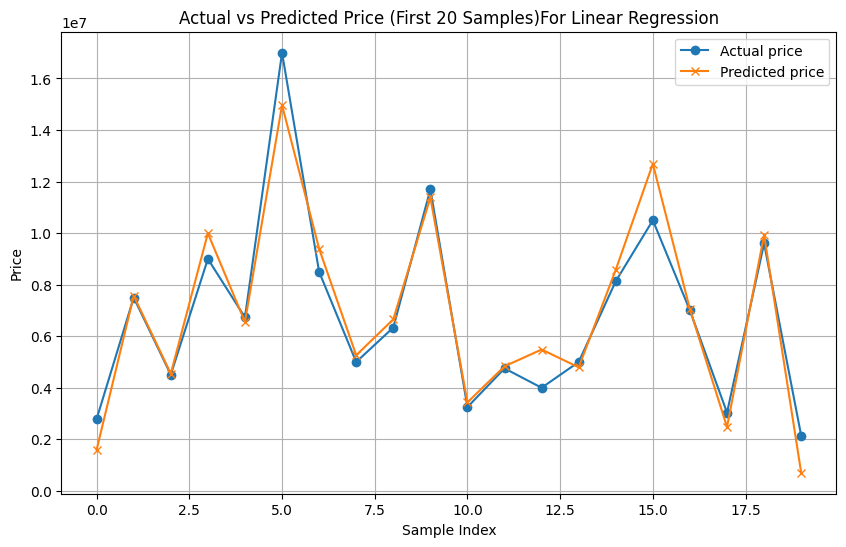

  7%|▋         | 1/15 [00:00<00:09,  1.55it/s]

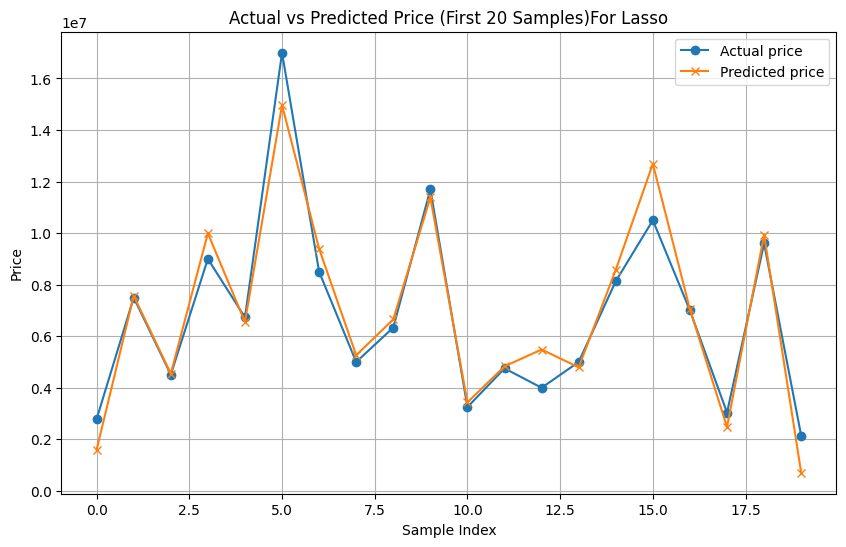

 13%|█▎        | 2/15 [00:01<00:06,  2.00it/s]

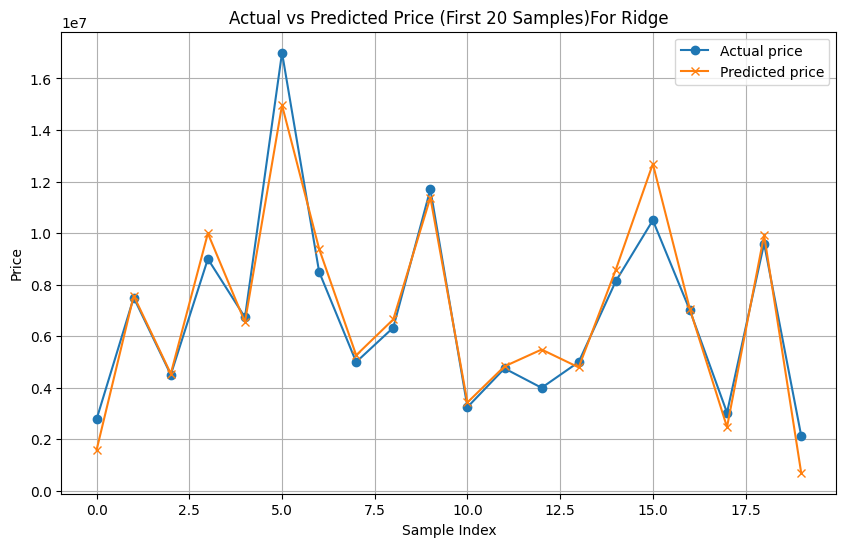

 20%|██        | 3/15 [00:01<00:05,  2.36it/s]

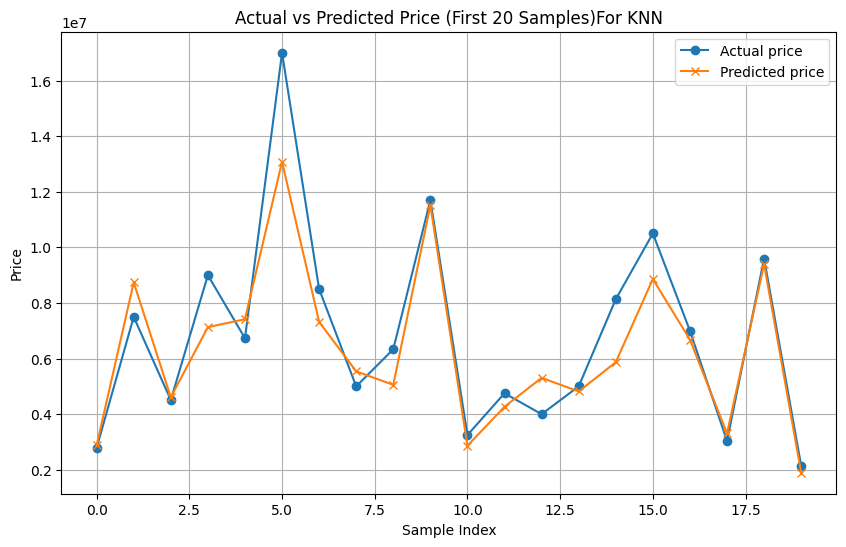

 27%|██▋       | 4/15 [00:02<00:06,  1.82it/s]

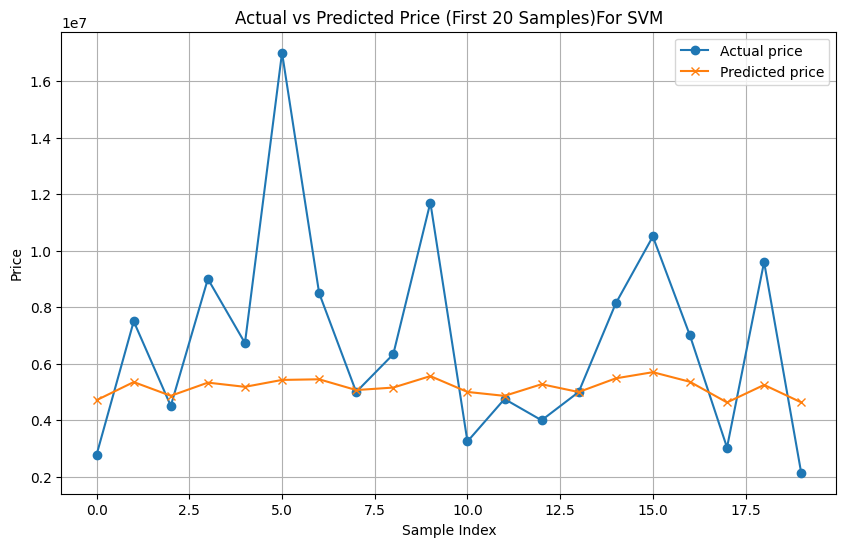

 33%|███▎      | 5/15 [00:05<00:14,  1.41s/it]

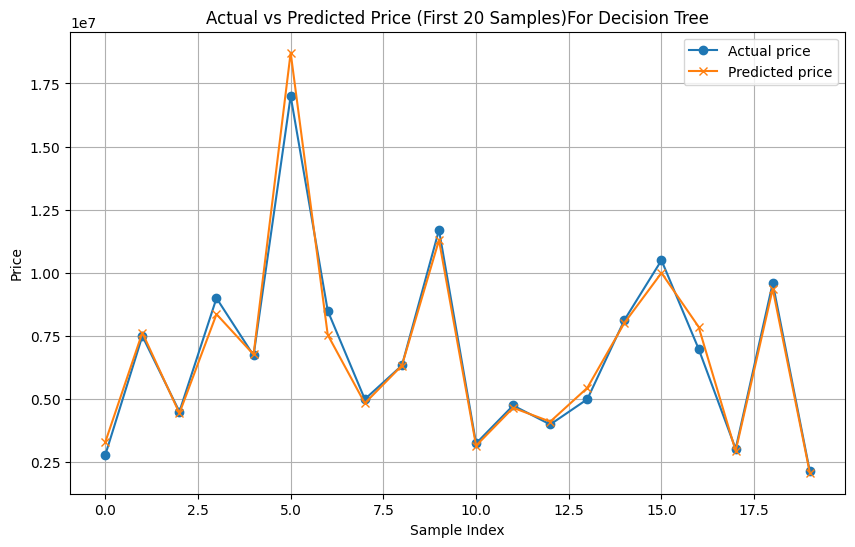

 40%|████      | 6/15 [00:05<00:10,  1.22s/it]

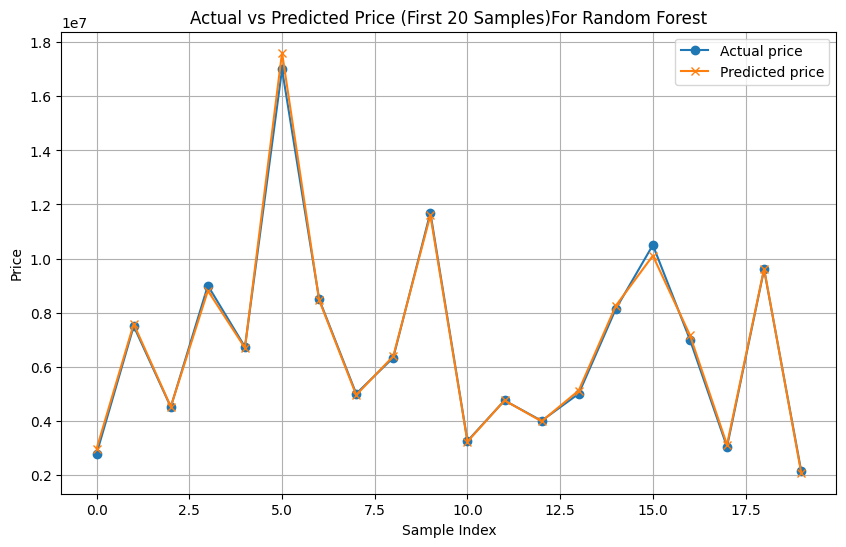

 47%|████▋     | 7/15 [00:08<00:12,  1.55s/it]

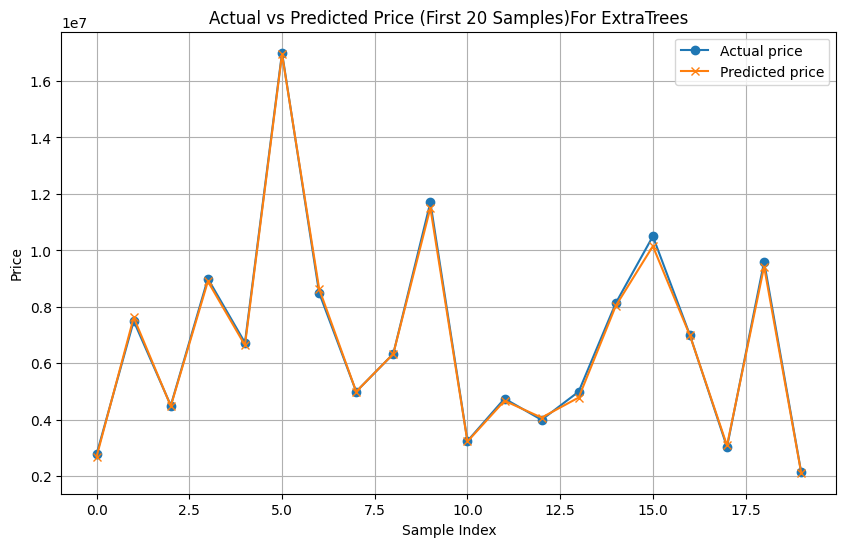

 53%|█████▎    | 8/15 [00:12<00:18,  2.60s/it]

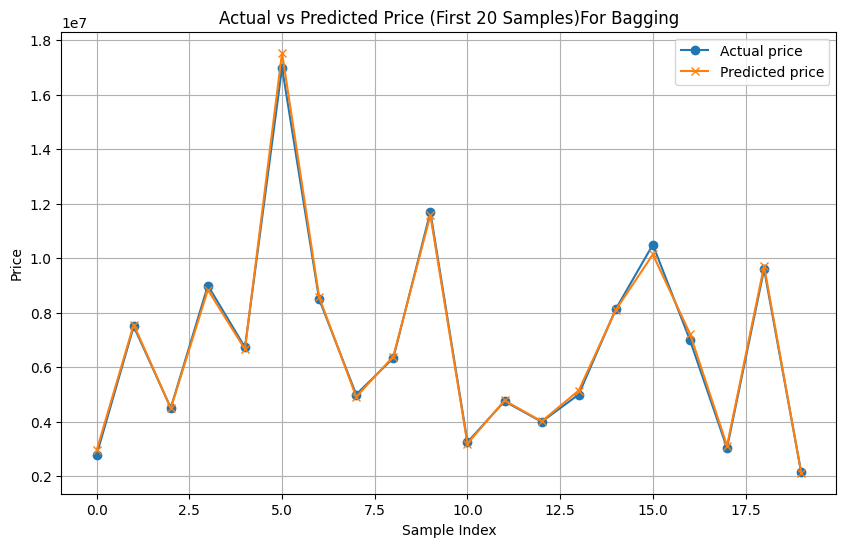

 60%|██████    | 9/15 [00:14<00:14,  2.37s/it]

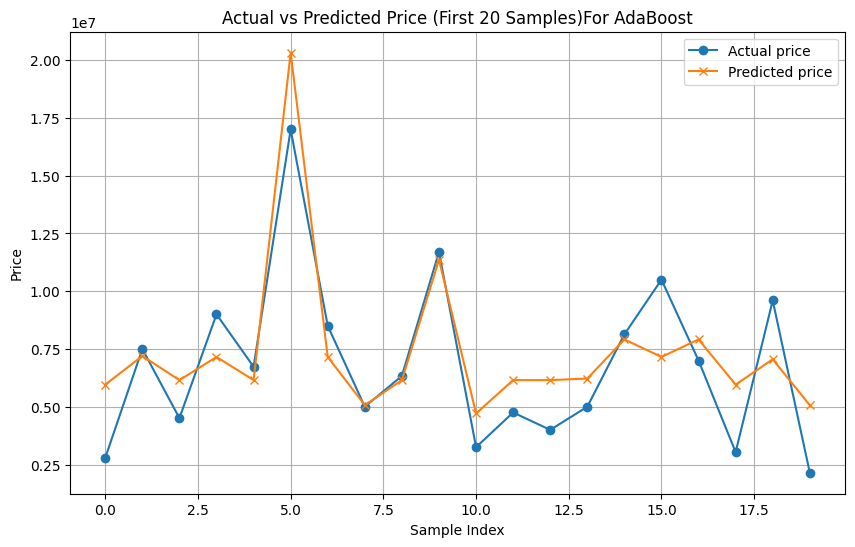

 67%|██████▋   | 10/15 [00:15<00:09,  1.83s/it]

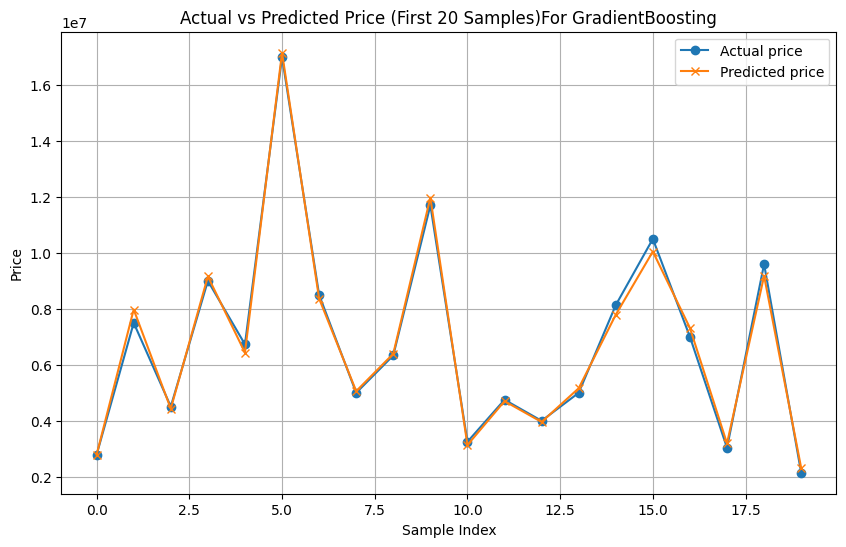

 73%|███████▎  | 11/15 [00:17<00:07,  1.92s/it]

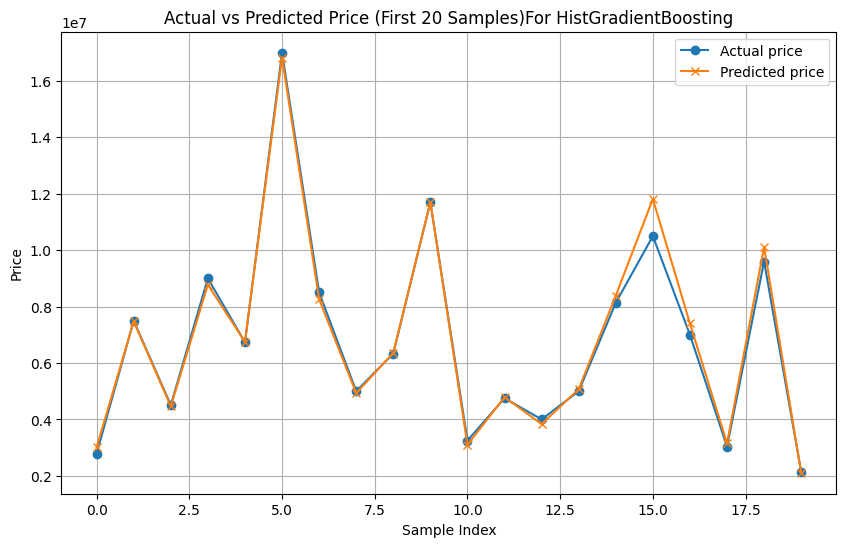

 80%|████████  | 12/15 [00:18<00:05,  1.75s/it]

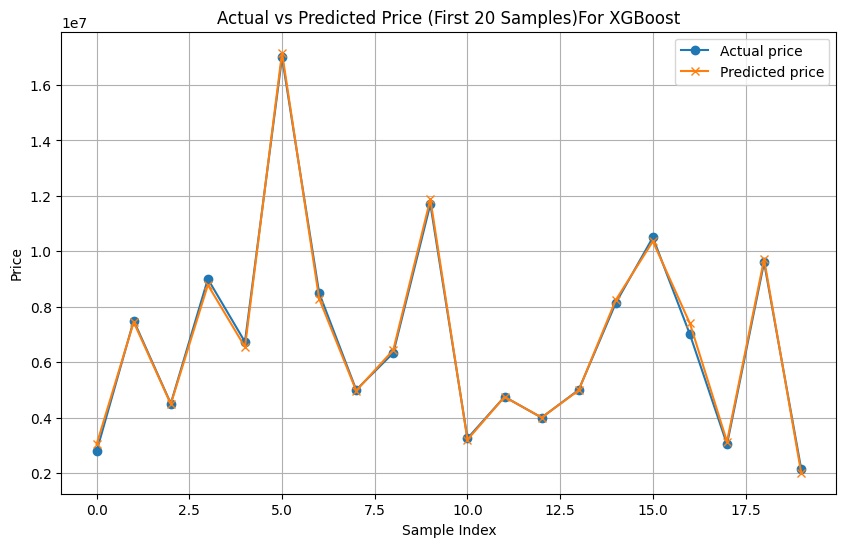

 87%|████████▋ | 13/15 [00:19<00:02,  1.43s/it]

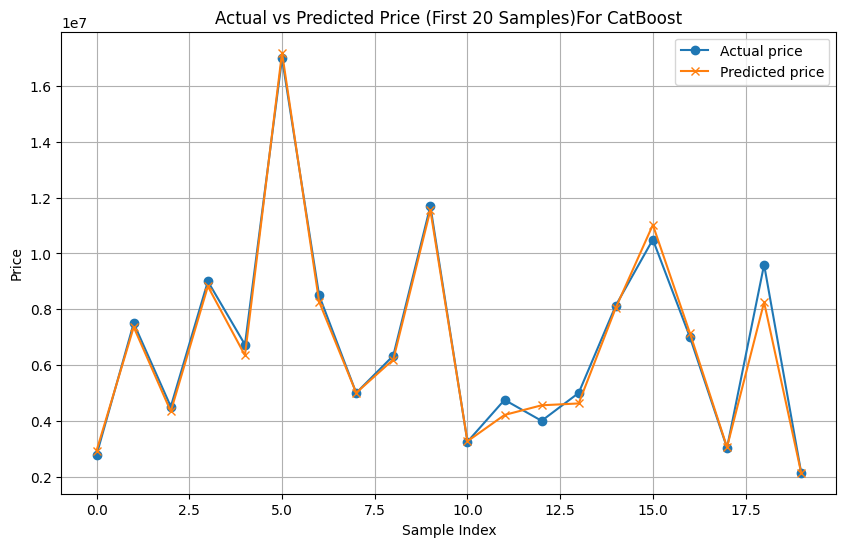

 93%|█████████▎| 14/15 [00:20<00:01,  1.25s/it]

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001771 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 576
[LightGBM] [Info] Number of data points in the train set: 3271, number of used features: 15
[LightGBM] [Info] Start training from score 6218563.863956


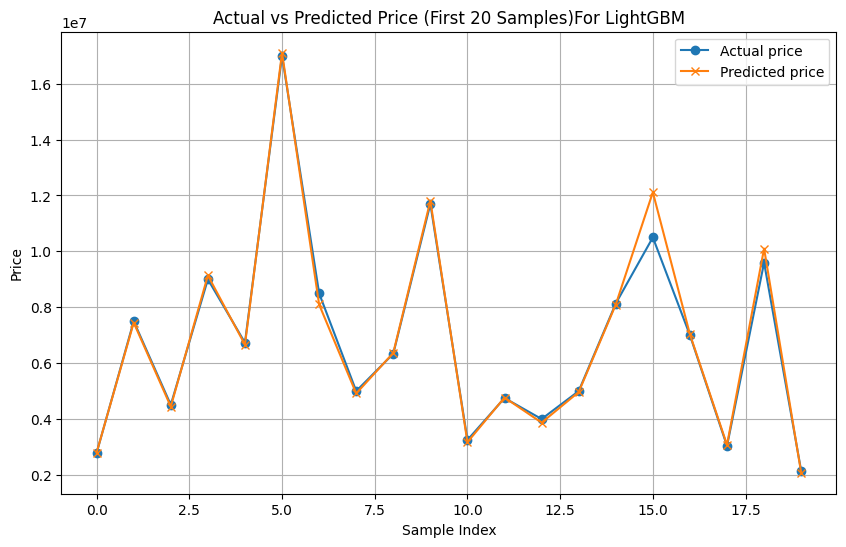

100%|██████████| 15/15 [00:21<00:00,  1.42s/it]


In [49]:
errors={}
for model_name , model in tqdm(models.items()):
    model.fit(X_train,y_train)
    MAE_Train, MSE_Train, RMSE_Train, R_Train = regression_metrics(model, X_train, y_train)
    MAE_Test, MSE_Test, RMSE_Test, R_Test = regression_metrics(model, X_test, y_test)
    
    errors[model_name] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R_Train,
        "R2 Test":R_Test
    }

    #Plotting Actual vs Predicted for first 20 test samples
    y_test_plot = y_test.values[:20]
    y_pred_plot = model.predict(X_test[:20])

    plt.figure(figsize=(10,6))
    plt.plot(range(20), y_test_plot, label='Actual price', marker='o')
    plt.plot(range(20), y_pred_plot, label='Predicted price', marker='x')
    plt.xlabel('Sample Index')
    plt.ylabel('Price')
    plt.title('Actual vs Predicted Price (First 20 Samples)For '+ model_name)
    plt.legend()
    plt.grid()
    plt.show()

In [50]:
# Create individual regressors
clf1 = LinearRegression()
clf2 = RandomForestRegressor(n_estimators=50, random_state=1)
clf3 = DecisionTreeRegressor(random_state=1)

# Voting Regressors (only averaging is supported)
model1 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
])

model2 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
])

# Weighted averaging
model3 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
], weights=[2, 1, 2])

# Fit models
model1.fit(X_train, y_train)
model2.fit(X_train, y_train)
model3.fit(X_train, y_train)


# Model 1
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model1, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(model1, X_test, y_test)

errors["Voting"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

# Model 2
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model2, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(model2, X_test, y_test)
errors["Simple Voting"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

# Model 3
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model3, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(model3, X_test, y_test)
errors["Weighted Voting"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }


In [51]:
# -----------------------------
# Base models for stacking
# -----------------------------
regressors = [
    ('rf', RandomForestRegressor(n_estimators=50, random_state=42)),
    ('gb', GradientBoostingRegressor(n_estimators=50, learning_rate=0.1, random_state=42)),
    ('cat', CatBoostRegressor(iterations=50, learning_rate=0.1, verbose=0)),
    ('lgb', LGBMRegressor(n_estimators=50, learning_rate=0.1, random_state=42))
]

# -----------------------------
# Meta-model
# -----------------------------
meta_regressor = XGBRegressor()

# -----------------------------
# Stacking Models
# -----------------------------
stacking_regressor = StackingRegressor(
    estimators=regressors,
    final_estimator=meta_regressor,
    cv=5,
    passthrough=True,
    n_jobs=-1
)


stacking_regressor.fit(X_train, y_train)
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(stacking_regressor, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(stacking_regressor, X_test, y_test)
errors["Stacking"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

In [52]:
errors_df = pd.DataFrame(errors).T.sort_values(by="R2 Test",ascending=False)
errors_df

,MAE Train,MAE Test,MSE Train,MSE Test,RMSE Train,RMSE Test,R2 Train,R2 Test
ExtraTrees,2.506879e+00,1.251361e+05,4.897585e+03,6.584202e+11,6.998275e+01,8.114310e+05,1.000000,0.975307
GradientBoosting,1.837992e+05,2.463440e+05,7.823882e+10,7.248321e+11,2.797120e+05,8.513707e+05,0.996223,0.972816
Voting,2.435168e+05,3.554512e+05,2.144076e+11,7.567710e+12,4.630416e+05,2.750947e+06,0.989650,0.969011
Simple Voting,2.435168e+05,3.554512e+05,2.144076e+11,7.567710e+12,4.630416e+05,2.750947e+06,0.989650,0.969011
Weighted Voting,2.891961e+05,3.554512e+05,2.760483e+11,7.567710e+12,5.254030e+05,2.750947e+06,0.986675,0.967180
Bagging,8.733974e+04,1.679368e+05,1.424721e+11,9.287453e+11,3.774547e+05,9.637144e+05,0.993123,0.965169
Stacking,9.282809e+04,3.554512e+05,5.842978e+11,7.567710e+12,7.643938e+05,2.750947e+06,0.971795,0.963330
XGBoost,9.492341e+04,2.158296e+05,2.115146e+10,1.061272e+12,1.454354e+05,1.030181e+06,0.998979,0.960199
Random Forest,8.691646e+04,1.799626e+05,1.696394e+11,1.193854e+12,4.118731e+05,1.092636e+06,0.991811,0.955227
Decision Tree,1.237891e+05,3.231526e+05,4.397502e+10,1.732100e+12,2.097022e+05,1.316093e+06,0.997877,0.935041


<Axes: >

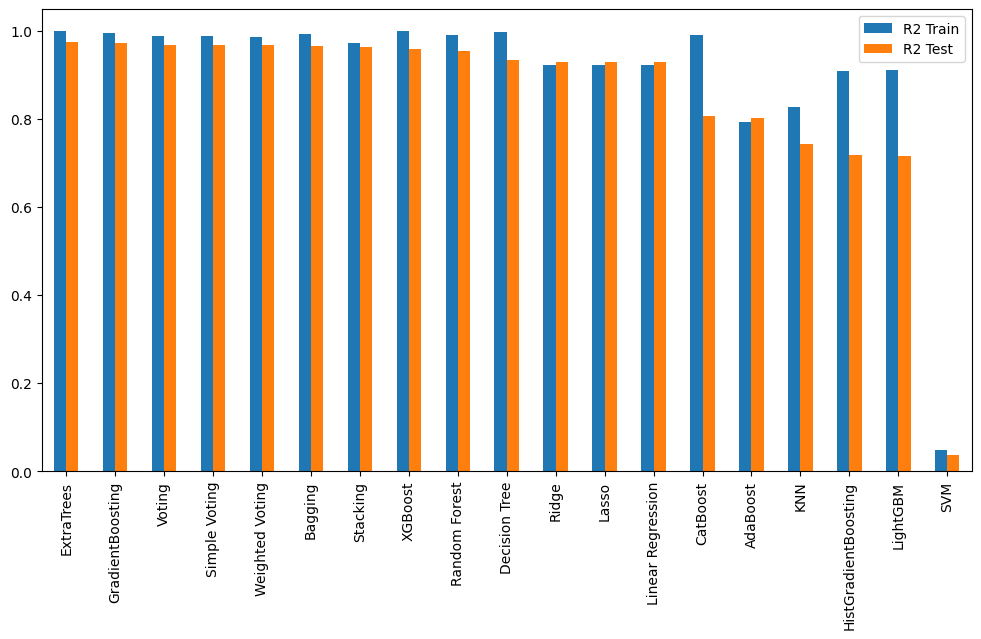

In [53]:
errors_df[["R2 Train", "R2 Test"]].plot.bar(figsize=(12,6))

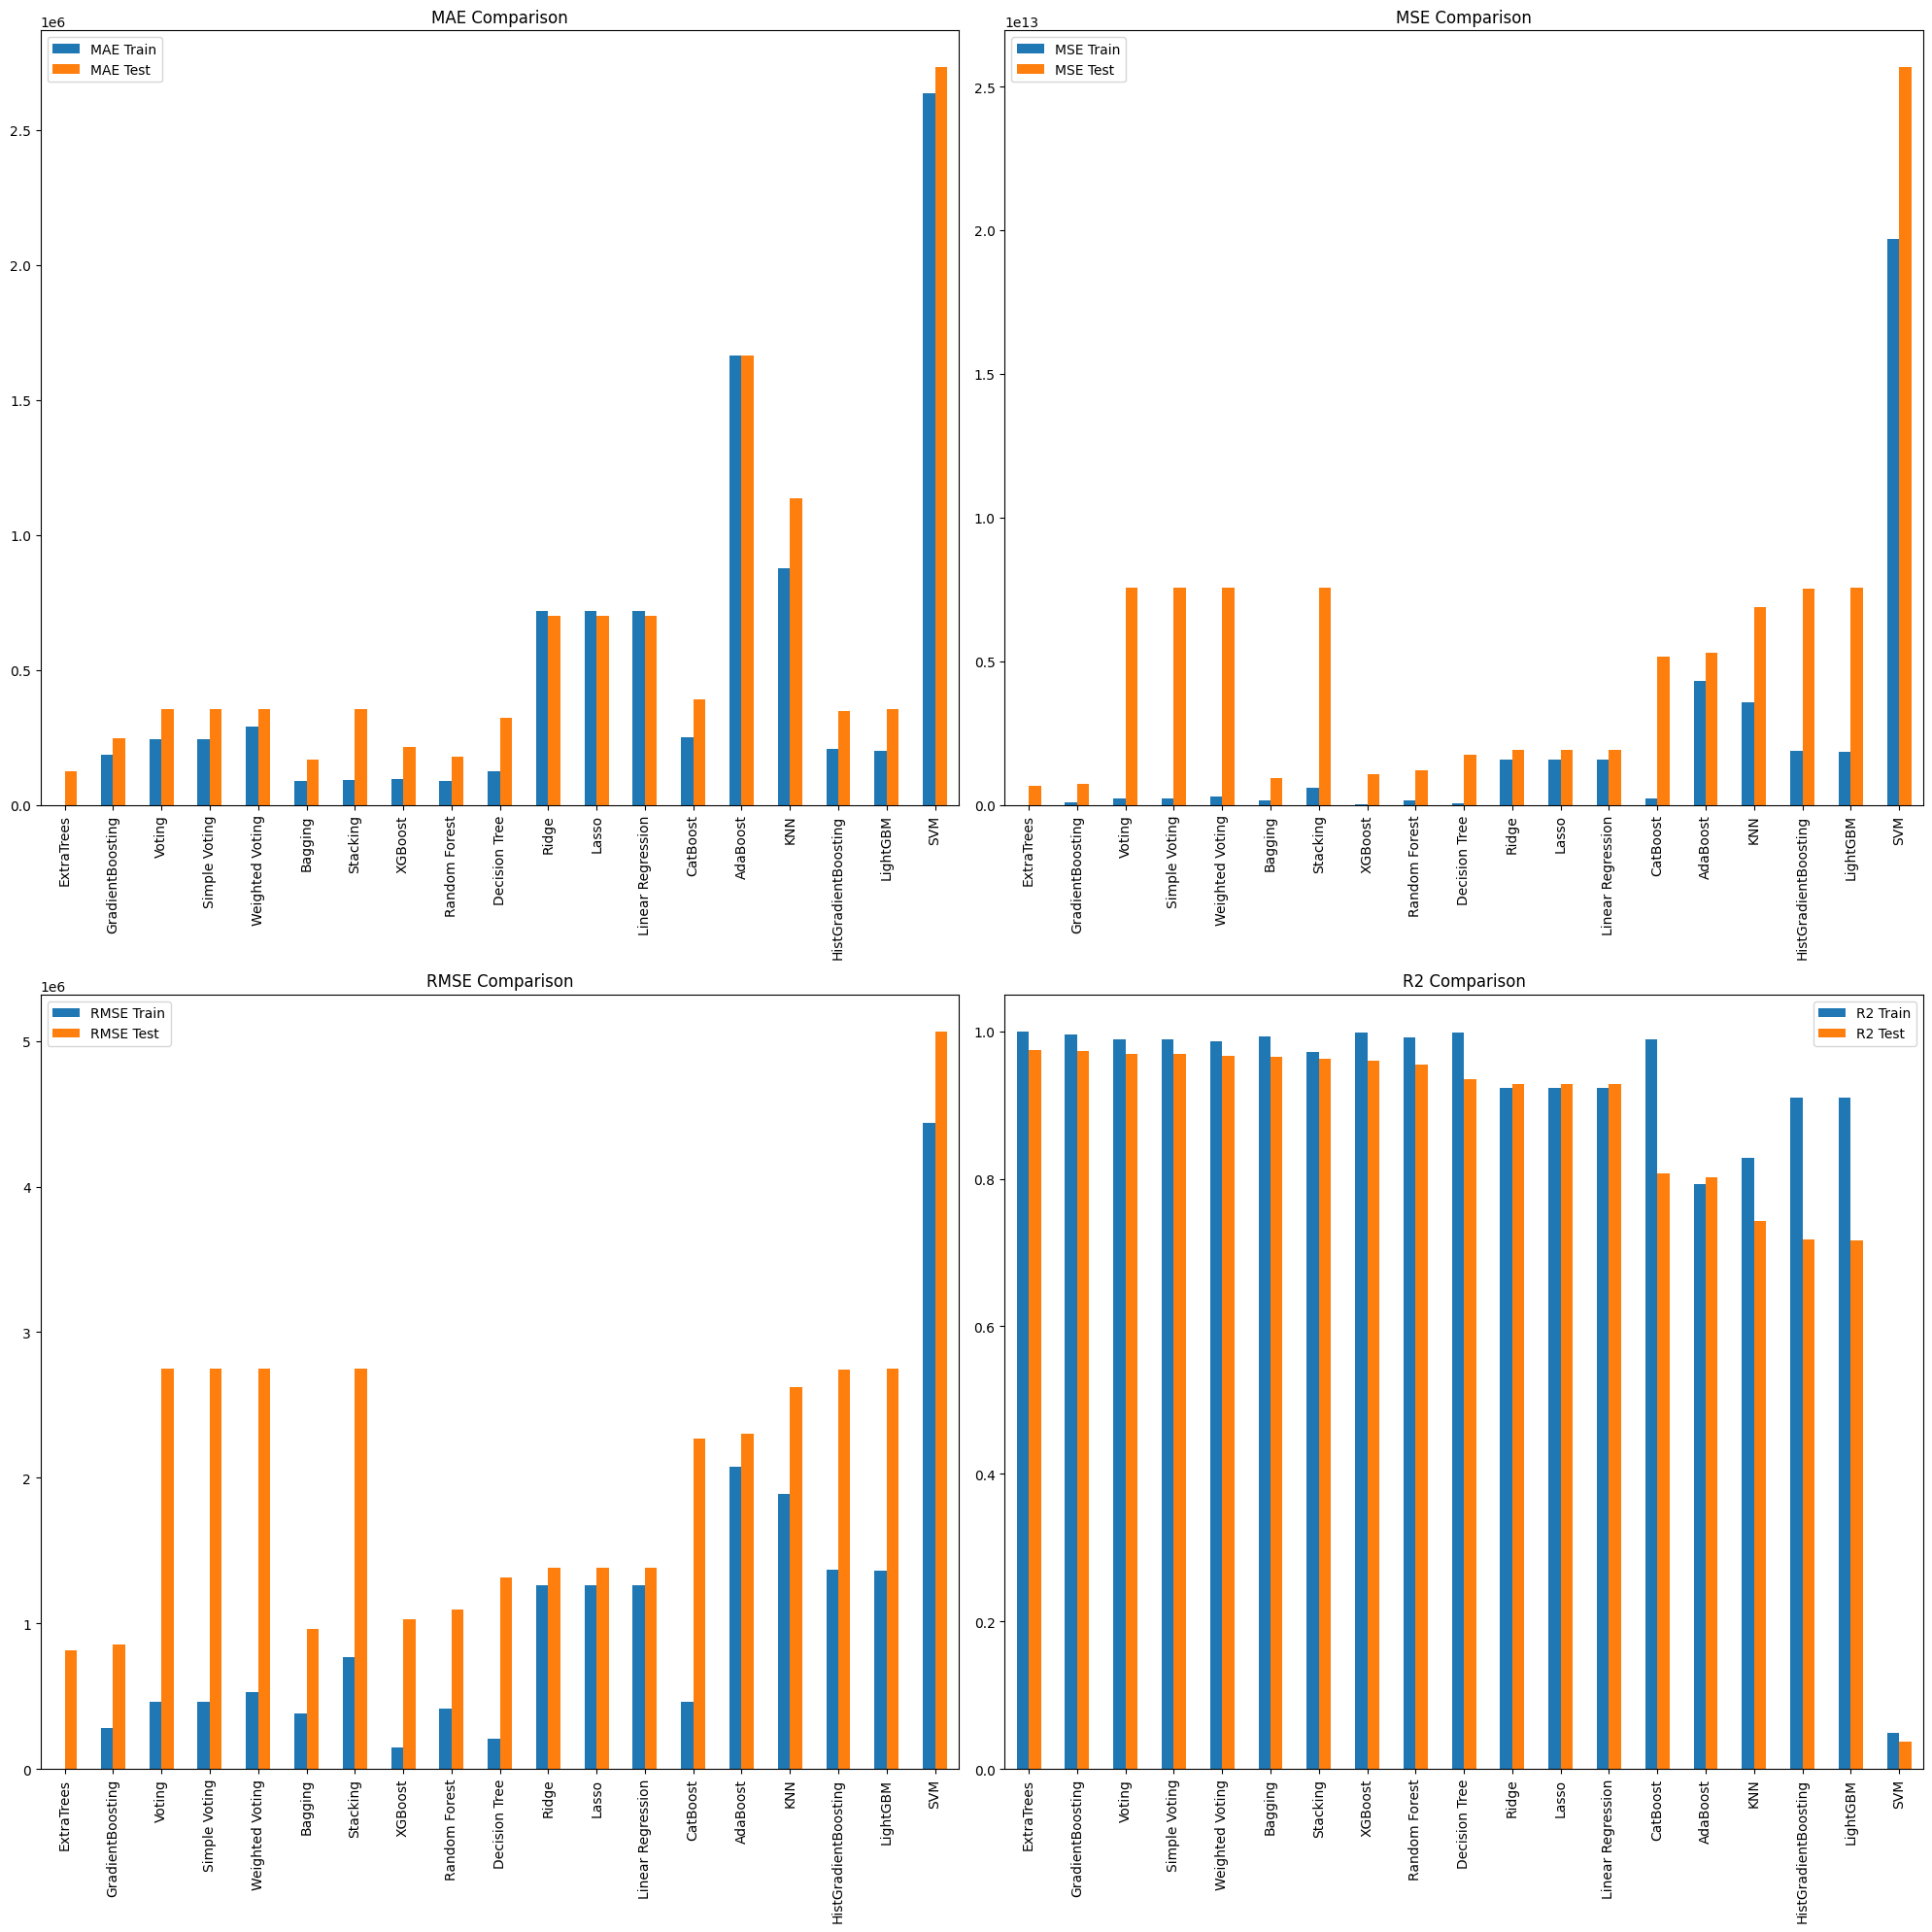

In [54]:
cols = [
    ['MAE Train', 'MAE Test'],
    ['MSE Train', 'MSE Test'],
    ['RMSE Train', 'RMSE Test'],
    ['R2 Train', 'R2 Test']
]

plt.figure(figsize=(20,20))

for i, col in enumerate(cols):
    ax = plt.subplot(2, 2, i+1)   
    errors_df[col].plot.bar(ax=ax)   
    ax.set_title(col[0].split(" ")[0] + ' Comparison')

plt.tight_layout()
plt.show()